## Initialization

#### Import Library, find available devices

In [1]:
# Initialization code for 3.3 V SiGe LVR Load Regulation Testing.
# This block identifies and initializes the connected SMUs (Source Measure Units).
# If running for the first time, ensure the SMU names are correctly referenced in the subsequent code block.

# This program sweeps VIN for a fixed VREF and measures total quiescent current (IQ) and VOUT. 
# This program sets up a directory for all measurements taken at a specific temperature by prompting the user for the temperature.
# This program creates a .csv file to save the measurements for a VREF in the temperature directory. 

# The setup assumes the use of two SMUs:
# - One dedicated to VIN sweeps.
# - One Sinks a load current and measures VOUT.

import pyvisa                    # Importing the pyvisa library for instrument communication
import time                      # Importing the time module to handle time-related tasks (e.g., delays)
import matplotlib.pyplot as plt  # Importing matplotlib.pyplot for plotting graphs and visualizing data
import numpy as np               # Importing numpy for numerical operations, particularly with arrays
import pandas as pd              # Importing pandas as pd for data manipulation and analysis
import os                        # Importing os to interact with the operating system, such as handling file paths
import csv                       # Importing csv to read from and write to CSV files
from IPython.display import display, clear_output
from datetime import date           # Importing date to read current date
from collections import defaultdict
from scipy.optimize import curve_fit

## Data

<Figure size 640x480 with 0 Axes>

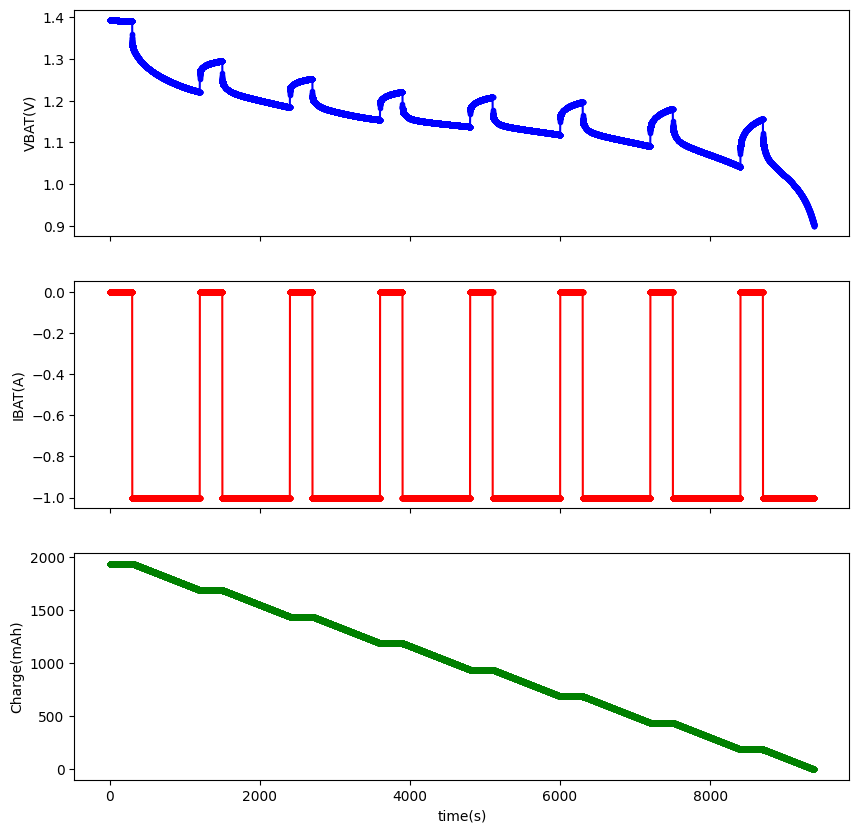

In [18]:
df = pd.read_csv("Test_1/complete.csv")
DOD = df["DOD"]
Charge = DOD - DOD[len(DOD)-1]
fig = plt.figure()
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(10, 10))
ax1.set_ylabel('VBAT(V)')
ax3.set_xlabel('time(s)')
ax2.set_ylabel('IBAT(A)')
ax3.set_ylabel('Charge(mAh)')

lineV, = ax1.plot([], [], '.-', color='blue')
lineV.set_data(df["times"], df["voltage"])
lineI, = ax2.plot([], [], '.-', color='red')
lineI.set_data(df["times"], df["current"])
lineDOD, = ax3.plot([], [], '.-', color='green')
lineDOD.set_data(df["times"], Charge)
ax1.relim()
ax1.autoscale_view()
ax2.relim()
ax2.autoscale_view()
ax3.relim()
ax3.autoscale_view()
display(fig)
clear_output(wait = True)

<Figure size 640x480 with 0 Axes>

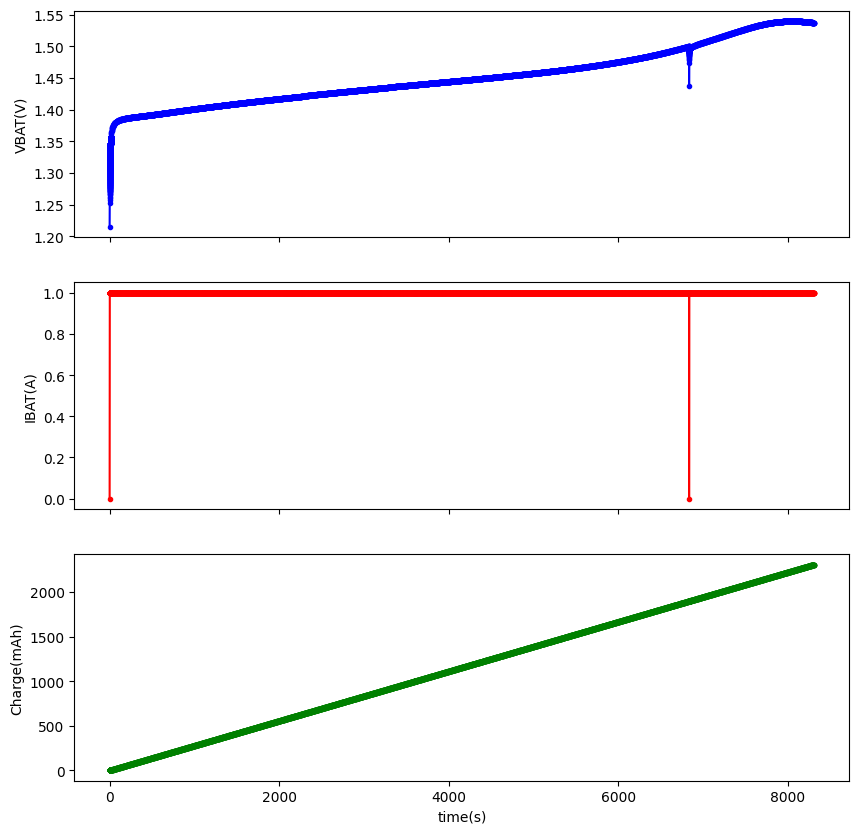

In [12]:
df = pd.read_csv("Charging_1/complete.csv")
df2 = pd.read_csv("Charging/complete.csv")
DOD = np.concatenate((df["DOD"], df2["DOD"]+df["DOD"][len(df)-1]))
Charge = DOD - DOD[len(DOD)-1]
fig = plt.figure()
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(10, 10))
ax1.set_ylabel('VBAT(V)')
ax3.set_xlabel('time(s)')
ax2.set_ylabel('IBAT(A)')
ax3.set_ylabel('Charge(mAh)')
times_combined= np.concatenate((df["times"], df2["times"]+df["times"][len(df)-1]))
voltage_combined = np.concatenate((df["voltage"], df2["voltage"]))
current_combined = np.concatenate((df["current"], df2["current"]))



lineV, = ax1.plot([], [], '.-', color='blue')
lineV.set_data(times_combined, voltage_combined)
lineI, = ax2.plot([], [], '.-', color='red')
lineI.set_data(times_combined, current_combined)
lineDOD, = ax3.plot([], [], '.-', color='green')
lineDOD.set_data(times_combined, DOD)
ax1.relim()
ax1.autoscale_view()
ax2.relim()
ax2.autoscale_view()
ax3.relim()
ax3.autoscale_view()
display(fig)
clear_output(wait = True)

save_dir = "Charging_combined"
os.makedirs(save_dir, exist_ok=True)
df = pd.DataFrame({'times': times_combined, 'voltage': voltage_combined, 'current': current_combined, 'DOD':DOD})
df.to_csv(os.path.join(save_dir, f'complete.csv'), index=False)

R1: 0.01 Ω, R2: 0.02 Ω, C1: 328.18 F, C2: 4342.14 F


<>:1: SyntaxWarning: invalid escape sequence '\S'
<>:1: SyntaxWarning: invalid escape sequence '\S'
C:\Users\lskarda\AppData\Local\Temp\ipykernel_48112\2224387763.py:1: SyntaxWarning: invalid escape sequence '\S'
  df = pd.read_csv("Test_1\SOC=1.2000326821555691.csv")


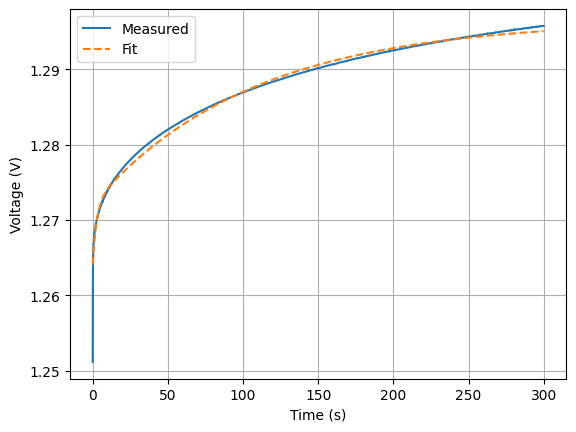

In [ ]:
df = pd.read_csv("Test_1\SOC=1.2000326821555691.csv")
times1 = df["times"]
VBAT1 = df["voltage"]
IBAT1 = df["current"]
DOD1 = df["DOD"]
IBAT1=IBAT1.values.tolist()

""" For the final curve in the discharge. It wasn't saved properly
index=32505
VBAT2= VBAT1.values.tolist()[index:]
IBAT2= IBAT1[index:]
DOD2= DOD1[index:]
times2= times1[index:]
index2 = IBAT2.index(-1)
VBAT= VBAT2[:index2]
IBAT= IBAT2[:index2]
DOD= DOD2[:index2]
times= times2[:index2]
times = times - times[index]
"""


index = IBAT1.index(-1)
#index= len(IBAT1)
VBAT= VBAT1.values.tolist()[:index]
IBAT= IBAT1[:index]
DOD= DOD1[:index]
times= times1[:index]
#index= len(IBAT)
times = times - times[0]


#Setup Plot
#fig = plt.figure()
# fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(10, 10))
# ax1.set_ylabel('VBAT(V)')
# ax3.set_xlabel('time(s)')
# ax2.set_ylabel('IBAT(A)')
# ax3.set_ylabel('DOD(mAh)')
# lineV, = ax1.plot([], [], '.-', color='blue')
# lineV.set_data(times, VBAT)
# lineI, = ax2.plot([], [], '.-', color='red')
# lineI.set_data(times, IBAT)
# lineDOD, = ax3.plot([], [], '.-', color='green')
# lineDOD.set_data(times, DOD)
# update_lines()

### Curve Fitting ###

def double_exp(t, A, B1, tau1, B2, tau2):
    return A + B1*np.exp(-t/tau1) + B2*np.exp(-t/tau2)


A0 = VBAT[-1]                  # final voltage
B1_0 = VBAT[0] - VBAT[-1]        # initial drop
B2_0 = 0.1 * B1_0

tau1_0 = 1
tau2_0 = 50

p0 = [A0, B1_0, tau1_0, B2_0, tau2_0]



popt, pcov = curve_fit(double_exp, times, VBAT, p0=p0, maxfev=10000)

A, B1, tau1, B2, tau2 = popt


I = 1.0

R1 = -B1 / I
R2 = -B2 / I

# time constants
# tau = R * C → C = tau / R

C1 = tau1 / R1
C2 = tau2 / R2
print(f"R1: {R1:.2f} Ω, R2: {R2:.2f} Ω, C1: {C1:.2f} F, C2: {C2:.2f} F")

v_fit = double_exp(times, *popt)

plt.plot(times, VBAT, label="Measured")
plt.plot(times, v_fit, '--', label="Fit")
plt.xlabel("Time (s)")
plt.ylabel("Voltage (V)")
plt.legend()
plt.grid()
plt.show()

